In [ ]:
import os
import torch
import numpy as np




DATA Augmentation

In [7]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform = A.Compose([
    A.Resize(512,512),

    A.HorizontalFlip(p=0.5),
 

    A.ShiftScaleRotate(
        shift_limit=0.03,
        scale_limit=0.05,
        rotate_limit=5,
        p=0.3
    ),

    A.ElasticTransform(
    alpha=10,
    sigma=5,
    alpha_affine=3,
    p=0.2
    ),
    A.GaussianBlur(blur_limit=(3,5), p=0.15),

    A.GaussNoise(p=0.2),

    A.RandomBrightnessContrast(p=0.2),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2(),
],

    additional_targets={"dist": "mask"} 
)

val_transform = A.Compose([
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),
    ToTensorV2(),
],
    additional_targets={"dist": "mask"} 

)


/tmp/ipykernel_2174705/4060132804.py:17: UserWarning: Argument 'alpha_affine' is not valid and will be ignored.
  A.ElasticTransform(


Dataset Loader

In [8]:
import os
import cv2
import numpy as np
from torch.utils.data import Dataset


class PlantSegDataset(Dataset):
    def __init__(self, image_dir, mask_dir, dist_dir, file_list, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.dist_dir = dist_dir
        self.file_list = file_list
        self.transform = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        name = self.file_list[idx]

        # -------- IMAGE --------
        img = cv2.imread(os.path.join(self.image_dir, name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # -------- MASK --------
        mask = cv2.imread(
            os.path.join(self.mask_dir, name),
            cv2.IMREAD_GRAYSCALE
        )
        mask = (mask > 0).astype("float32")

        # -------- DIST --------
        base_name = os.path.splitext(name)[0]
        dist_path = os.path.join(self.dist_dir, base_name + ".npy")
        dist = np.load(dist_path).astype("float32")

        # -------- TRANSFORM --------
        if self.transform:
            augmented = self.transform(image=img, mask=mask, dist=dist)
            img = augmented["image"]      # tensor
            mask = augmented["mask"]      # tensor\
            dist = augmented["dist"]

        if dist.max() > 0:
            dist = dist / (dist.max() + 1e-6)
        #  normalize ALL tensors
        img = img.contiguous()
        mask = mask.unsqueeze(0).float().contiguous()
        dist = dist.unsqueeze(0).float().contiguous()

        return img, mask, dist

Accuracy calculation and matrices

In [9]:
import torch
import torch.nn.functional as F


#  Log Dice Loss (better for thin structures)
def dice_loss(pred, target, smooth=1e-6):

    pred = torch.sigmoid(pred)
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    # log version stabilizes training
    return -torch.log(dice + 1e-6).mean()


def combined_loss(pred, mask, dist):

    pos_weight = torch.tensor([5.0], device=pred.device)

    bce = F.binary_cross_entropy_with_logits(
        pred, mask, pos_weight=pos_weight
    )

    dloss = dice_loss(pred, mask)

    pred_prob = torch.sigmoid(pred)
    dist_loss = F.l1_loss(pred_prob, dist)

    return 0.8 * dloss + 0.1 * bce + 0.1 * dist_loss


# Soft Dice Score (NO threshold → true learning signal)
def dice_score(pred, target, smooth=1e-6):

    pred = torch.sigmoid(pred)

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    return dice.mean()


#  Hard metrics (for reporting only)
def segmentation_metrics(pred, target, threshold=0.4):

    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    union = pred.sum(dim=1) + target.sum(dim=1) - intersection

    iou = (intersection + 1e-6) / (union + 1e-6)

    precision = (intersection + 1e-6) / (pred.sum(dim=1) + 1e-6)

    recall = (intersection + 1e-6) / (target.sum(dim=1) + 1e-6)

    return iou.mean(), precision.mean(), recall.mean()

Model Architecture

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm


# -------------------------------------------------------
# Attention Gate
# -------------------------------------------------------

class AttentionBlock(nn.Module):
    def __init__(self, x_channels, g_channels, inter_channels):
        super().__init__()

        self.theta = nn.Conv2d(x_channels, inter_channels, 1)
        self.phi   = nn.Conv2d(g_channels, inter_channels, 1)
        self.psi   = nn.Conv2d(inter_channels, 1, 1)

        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, g):

        theta = self.theta(x)
        phi   = self.phi(g)

        attn = self.relu(theta + phi)
        attn = self.sigmoid(self.psi(attn))

        return x * attn


# -------------------------------------------------------
# Conv Block 
# -------------------------------------------------------

class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm1 = nn.GroupNorm(32, out_c)

        self.conv2 = nn.Conv2d(
            out_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm2 = nn.GroupNorm(32, out_c)

        self.conv3 = nn.Conv2d(
            out_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm3 = nn.GroupNorm(32, out_c)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout2d(0.2)

        # Match channels for residual connection
        if in_c != out_c:
            self.residual = nn.Sequential(
                nn.Conv2d(
                    in_c,
                    out_c,
                    kernel_size=1,
                    bias=False
                ),
                nn.GroupNorm(32, out_c)
            )
        else:
            self.residual = nn.Identity()

    def forward(self, x):

        identity = self.residual(x)

        out = self.relu(self.norm1(self.conv1(x)))
        out = self.relu(self.norm2(self.conv2(out)))
        out = self.norm3(self.conv3(out))

        out = out + identity
        out = self.relu(out)

        out = self.dropout(out)

        return out


# -------------------------------------------------------
# Decoder Block
# -------------------------------------------------------

class DecoderBlock(nn.Module):

    def __init__(self,
                 in_channels,
                 skip_channels,
                 out_channels):

        super().__init__()

        self.att = AttentionBlock(
            x_channels=skip_channels,
            g_channels=in_channels,
            inter_channels=skip_channels,
        )

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        skip = self.att(skip, x)

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


# -------------------------------------------------------
# Refinement Block
# -------------------------------------------------------

class RefinementBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = ConvBlock(
            in_channels,
            out_channels
        )

    def forward(self, x):

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        return self.conv(x)


# -------------------------------------------------------
# ConvNeXt Tiny Attention U-Net
# -------------------------------------------------------

class ConvNeXtUNet(nn.Module):

    def __init__(self):

        super().__init__()

        # ---------------- Encoder ----------------

        self.encoder = timm.create_model(
            "convnext_tiny",
            pretrained=True,
            features_only=True,
            out_indices=(0,1,2,3)
        )

        # channels
        # e1 = 96
        # e2 = 192
        # e3 = 384
        # e4 = 768

        # ---------------- Decoder ----------------

        self.dec4 = DecoderBlock(
            in_channels=768,
            skip_channels=384,
            out_channels=384
        )

        self.dec3 = DecoderBlock(
            in_channels=384,
            skip_channels=192,
            out_channels=192
        )

        self.dec2 = DecoderBlock(
            in_channels=192,
            skip_channels=96,
            out_channels=96
        )

        # no skip connections

        self.ref1 = RefinementBlock(
            96,
            64
        )

        self.ref0 = RefinementBlock(
            64,
            64
        )

        self.final = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

        self.final.bias.data.fill_(-2.0)

    def forward(self, x):

        # ---------------- Encoder ----------------

        e1, e2, e3, e4 = self.encoder(x)

        # e1 : 96 x128
        # e2 : 192 x64
        # e3 : 384 x32
        # e4 : 768 x16

        # ---------------- Decoder ----------------

        d4 = self.dec4(e4, e3)   # 384 x32

        d3 = self.dec3(d4, e2)   # 192 x64

        d2 = self.dec2(d3, e1)   # 96 x128

        d1 = self.ref1(d2)       # 64 x256

        d0 = self.ref0(d1)       # 64 x512

        out = self.final(d0)

        return out

Sliding window patching

In [11]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset


class SlidingWindowPatchDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        dist_dir, 
        files,
        transform=None,
        patch_size=512,
        stride=256,
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.dist_dir = dist_dir  
        self.files = files
        self.transform = transform
        self.patch_size = patch_size
        self.stride = stride

        self.samples = []

        for name in self.files:

            img = cv2.imread(f"{self.image_dir}/{name}")
            H, W = img.shape[:2]

            p = self.patch_size
            s = self.stride

            y_positions = list(range(0, H - p + 1, s))
            x_positions = list(range(0, W - p + 1, s))

            if y_positions[-1] != H - p:
                y_positions.append(H - p)

            if x_positions[-1] != W - p:
                x_positions.append(W - p)

            for y in y_positions:
                for x in x_positions:
                    self.samples.append((name, y, x))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        name, y, x = self.samples[idx]

        img = cv2.imread(f"{self.image_dir}/{name}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(
            f"{self.mask_dir}/{name}",
            cv2.IMREAD_GRAYSCALE
        )
        mask = (mask > 0).astype("float32")

        # LOAD DISTANCE
        base_name = os.path.splitext(name)[0]
        dist_path = os.path.join(self.dist_dir, base_name + ".npy")

        if not os.path.exists(dist_path):
            raise ValueError(f"Missing dist file: {dist_path}")

        dist = np.load(dist_path).astype("float32")


        p = self.patch_size

        crop_img = img[y:y+p, x:x+p]
        crop_mask = mask[y:y+p, x:x+p]
        crop_dist = dist[y:y+p, x:x+p]

        # -------- TRANSFORM --------
        if self.transform:
            aug = self.transform(
                image=crop_img,
                mask=crop_mask,
                dist=crop_dist
            )
            crop_img = aug["image"]
            crop_mask = aug["mask"]
            crop_dist = aug["dist"]

        if crop_dist.max() > 0:
            crop_dist = crop_dist / (crop_dist.max() + 1e-6)
        # -------- FINAL --------
        crop_img = crop_img.contiguous()
        crop_mask = crop_mask.unsqueeze(0).float().contiguous()
        crop_dist = crop_dist.unsqueeze(0).float().contiguous()

        return crop_img, crop_mask, crop_dist

Train test split 

In [12]:
from sklearn.model_selection import train_test_split
import os

image_dir1 = "../DATA/saplingsMix"
mask_dir1 = "../DATA/maskeMix"
dist_dir1 = "../DATA/distanceMix"

image_dir2 = "../DATA/saplings7"
mask_dir2 = "../DATA/masked3"
dist_dir2 = "../DATA/distance7"

all_files1 = sorted(os.listdir(image_dir1))
all_files2 = sorted(os.listdir(image_dir2))


train_files2, val_files2 = train_test_split(
    all_files2,
    test_size=0.2,
    random_state=42
)



Data loader

In [13]:
from torch.utils.data import DataLoader

# -------------------------
# PHASE 1 TRAINING DATASET
# (single sapling images)
# -------------------------

train_ds1 = PlantSegDataset(
    image_dir1,
    mask_dir1,
    dist_dir1,
    all_files1,
    train_transform
)

train_loader1 = DataLoader(
    train_ds1,
    batch_size=4,
    shuffle=True,
    num_workers=2
)


# -------------------------
# PHASE 2 TRAINING DATASET
# (multi-sapling patches)
# -------------------------

train_ds2 = SlidingWindowPatchDataset(
    image_dir=image_dir2,
    mask_dir=mask_dir2,
    dist_dir=dist_dir2, 
    files=train_files2,
    transform=train_transform,
    patch_size=512,
    stride=256
)

train_loader2 = DataLoader(
    train_ds2,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)


# -------------------------
# VALIDATION DATASET
# (FULL multi-sapling images)
# -------------------------

val_ds = SlidingWindowPatchDataset(
    image_dir=image_dir2,
    mask_dir=mask_dir2,
    dist_dir=dist_dir2, 
    files=val_files2,
    transform=val_transform,
    patch_size=512,
    stride=256
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

Sliding window inference

In [14]:
import torch


def get_weight_map(size, device):
    coords = torch.linspace(-1, 1, size, device=device)
    yy, xx = torch.meshgrid(coords, coords, indexing='ij')
    weight = torch.exp(-(xx**2 + yy**2) / 0.5)
    return weight.unsqueeze(0).unsqueeze(0)


def sliding_window_inference(
    model,
    image,
    window_size=512,
    overlap=0.5,
    batch_size=8   
):
    device = image.device
    _, _, H, W = image.shape

    stride = int(window_size * (1 - overlap))
    stride = max(1, stride)

    pred_mask = torch.zeros((1, 1, H, W), device=device)
    count_map = torch.zeros((1, 1, H, W), device=device)

    weight_map = get_weight_map(window_size, device)

    y_positions = list(range(0, H - window_size + 1, stride))
    x_positions = list(range(0, W - window_size + 1, stride))

    if y_positions[-1] != H - window_size:
        y_positions.append(H - window_size)

    if x_positions[-1] != W - window_size:
        x_positions.append(W - window_size)

    # ---------------- COLLECT PATCHES ----------------
    patches = []
    coords = []

    for y in y_positions:
        for x in x_positions:
            patch = image[:, :, y:y+window_size, x:x+window_size]
            patches.append(patch)
            coords.append((y, x))

    patches = torch.cat(patches, dim=0)  # [N, 3, 512, 512]

    # ---------------- BATCH INFERENCE ----------------
    preds = []

    for i in range(0, patches.size(0), batch_size):
        batch = patches[i:i+batch_size]

        pred = model(batch)
        pred = torch.sigmoid(pred)

        preds.append(pred)

    preds = torch.cat(preds, dim=0)  # [N, 1, 512, 512]

    # ---------------- STITCH BACK ----------------
    for i, (y, x) in enumerate(coords):
        pred_mask[:, :, y:y+window_size, x:x+window_size] += preds[i:i+1] * weight_map
        count_map[:, :, y:y+window_size, x:x+window_size] += weight_map

    pred_mask = pred_mask / torch.clamp(count_map, min=1e-6)

    return pred_mask

In [16]:
import torch
import torch.nn as nn

phase1_epochs = 25
phase2_epochs = 75
total_epochs = phase1_epochs + phase2_epochs

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- MODEL ----------------
model = ConvNeXtUNet().to(device)


# ---------------- FREEZE (PHASE 1) ----------------
# Freeze entire encoder
for p in model.encoder.parameters():
    p.requires_grad = False

# Train only the deepest stage
for p in model.encoder.stages_3.parameters():
    p.requires_grad = True

# ---------------- OPTIMIZER BUILDER ----------------
def build_optimizer(model,
                    lr_low=5e-6,
                    lr_high=1e-5,
                    lr_dec=1e-4):

    enc_low = []
    enc_high = []
    decoder = []

    for name, param in model.named_parameters():

        if not param.requires_grad:
            continue

        if "encoder.stages_0" in name or "encoder.stages_1" in name:
            enc_low.append(param)

        elif "encoder.stages_2" in name or "encoder.stages_3" in name:
            enc_high.append(param)

        else:
            decoder.append(param)

    return torch.optim.AdamW(
        [
            {"params": enc_low, "lr": lr_low},
            {"params": enc_high, "lr": lr_high},
            {"params": decoder, "lr": lr_dec},
        ],
        weight_decay=1e-4
    )

# ---------------- OPTIMIZER INIT ----------------
optimizer = build_optimizer(model)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.8,
    patience=6,
    min_lr=1e-6
)

# ---------------- METRICS STORAGE ----------------
train_loss_history = []
val_loss_history = []

train_dice_history = []
val_dice_history = []

val_iou_history = []
val_precision_history = []
val_recall_history = []

best_val_dice = 0.0


# ---------------- TRAINING LOOP ----------------
for epoch in range(total_epochs):

    # ---------------- DATASET PHASE ----------------
    if epoch < phase1_epochs:
        train_loader = train_loader1
        phase = "Single Saplings"
    else:
        train_loader = train_loader2
        phase = "Multi Saplings (Sliding Window Patches)"

    print(f"\nEpoch {epoch+1}/{total_epochs} | {phase}\n")

    # ---------------- PHASE 2: UNFREEZE MID ENCODER ----------------
    if epoch == 35:
        print("\nUnfreezing deeper encoder (enc3–enc5)\n")

        for p in model.encoder.stages_2.parameters():
            p.requires_grad = True

        optimizer = build_optimizer(
            model,
            lr_low=5e-6,
            lr_high=1e-5,
            lr_dec=8e-5
        )

        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.8,
            patience=6,
            min_lr=1e-6
        )
    # ---------------- PHASE 3: FULL UNFREEZE ----------------
    if epoch == 60:
        print("\nFull encoder fine-tuning\n")

        for p in model.encoder.parameters():
            p.requires_grad = True

        optimizer = build_optimizer(
            model,
            lr_low=5e-6,
            lr_high=8e-6,
            lr_dec=5e-5
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.8,
            patience=6,
            min_lr=1e-6
        )

    # ---------------- TRAIN ----------------
    model.train()

    train_loss = 0
    train_dice = 0

    for img, mask, dist in train_loader:

        img = img.to(device)
        mask = mask.to(device).float()
        dist = dist.to(device).float()

        pred = model(img)

        loss = combined_loss(pred, mask, dist)
        dice = dice_score(pred, mask)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        train_loss += loss.item()
        train_dice += dice.item()

    train_loss /= len(train_loader)
    train_dice /= len(train_loader)

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0
    val_dice = 0
    val_iou = 0
    val_precision = 0
    val_recall = 0

    with torch.no_grad():

         for img, mask, dist in val_loader:

            img = img.to(device)
            mask = mask.to(device).float()
            dist = dist.to(device).float()

            pred = model(img)

            loss = combined_loss(pred, mask, dist)
            dice = dice_score(pred, mask)

            iou, precision, recall = segmentation_metrics(pred, mask)

            val_loss += loss.item()
            val_dice += dice.item()
            val_iou += iou.item()
            val_precision += precision.item()
            val_recall += recall.item()

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)
    val_precision /= len(val_loader)
    val_recall /= len(val_loader)

    # ---------------- STORE HISTORY ----------------
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    train_dice_history.append(train_dice)
    val_dice_history.append(val_dice)

    val_iou_history.append(val_iou)
    val_precision_history.append(val_precision)
    val_recall_history.append(val_recall)

    # ---------------- LR SCHEDULER ----------------
    scheduler.step(val_dice)

    # ---------------- SAVE BEST ----------------
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save(model.state_dict(), "convnext_unet_1.pth")

   

    # ---------------- LOG ----------------
    print(
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f}"
    )


Epoch 1/100 | Single Saplings

Train Dice: 0.2982 | Val Dice: 0.4187 | IoU: 0.3243 | Precision: 0.4886 | Recall: 0.6427

Epoch 2/100 | Single Saplings

Train Dice: 0.5675 | Val Dice: 0.4648 | IoU: 0.3563 | Precision: 0.5265 | Recall: 0.6608

Epoch 3/100 | Single Saplings

Train Dice: 0.6625 | Val Dice: 0.4765 | IoU: 0.4392 | Precision: 0.6430 | Recall: 0.6445

Epoch 4/100 | Single Saplings

Train Dice: 0.7101 | Val Dice: 0.4984 | IoU: 0.3832 | Precision: 0.5527 | Recall: 0.6963

Epoch 5/100 | Single Saplings

Train Dice: 0.7351 | Val Dice: 0.4535 | IoU: 0.3409 | Precision: 0.5933 | Recall: 0.5928

Epoch 6/100 | Single Saplings

Train Dice: 0.7716 | Val Dice: 0.4535 | IoU: 0.3605 | Precision: 0.6116 | Recall: 0.5938

Epoch 7/100 | Single Saplings

Train Dice: 0.7902 | Val Dice: 0.4627 | IoU: 0.4179 | Precision: 0.6731 | Recall: 0.6007

Epoch 8/100 | Single Saplings

Train Dice: 0.8010 | Val Dice: 0.4716 | IoU: 0.3557 | Precision: 0.5728 | Recall: 0.6290

Epoch 9/100 | Single Saplings



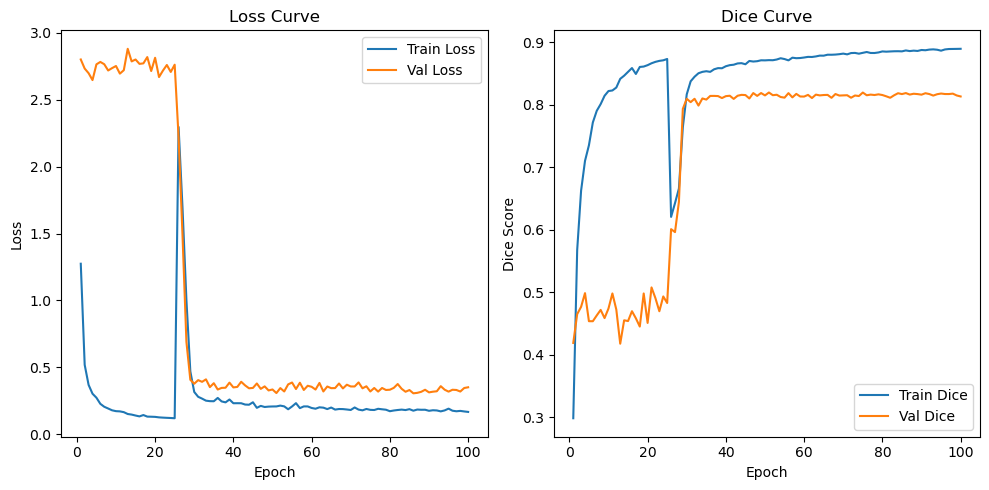

In [17]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(10, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss_history, label="Train Loss")
plt.plot(epochs, val_loss_history, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

# Dice
plt.subplot(1, 2, 2)
plt.plot(epochs, train_dice_history, label="Train Dice")
plt.plot(epochs, val_dice_history, label="Val Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("Dice Curve")
plt.legend()

plt.tight_layout()
plt.show()

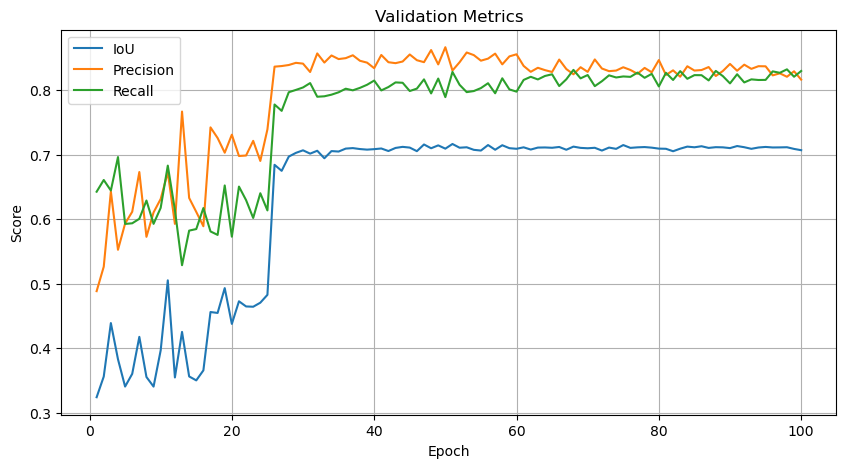

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(epochs, val_iou_history, label="IoU")
plt.plot(epochs, val_precision_history, label="Precision")
plt.plot(epochs, val_recall_history, label="Recall")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics")
plt.legend()
plt.grid(True)

plt.show()

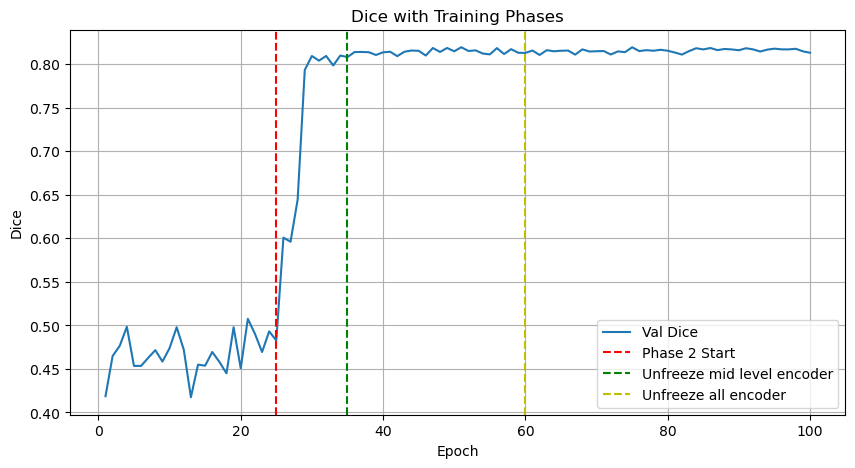

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(epochs, val_dice_history, label="Val Dice")

plt.axvline(x=25, color='r', linestyle='--', label='Phase 2 Start')
plt.axvline(x=35, color='g', linestyle='--', label='Unfreeze mid level encoder')
plt.axvline(x=60, color='y', linestyle='--', label='Unfreeze all encoder')

plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Dice with Training Phases")
plt.legend()
plt.grid(True)

plt.show()

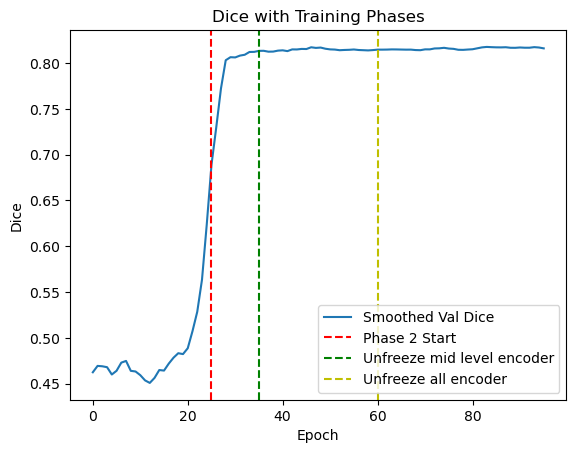

: 

In [ ]:
import numpy as np

def smooth(y, window=5):
    return np.convolve(y, np.ones(window)/window, mode='valid')

plt.plot(smooth(val_dice_history), label="Smoothed Val Dice")
plt.axvline(x=25, color='r', linestyle='--', label='Phase 2 Start')
plt.axvline(x=35, color='g', linestyle='--', label='Unfreeze mid level encoder')
plt.axvline(x=60, color='y', linestyle='--', label='Unfreeze all encoder')

plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Dice with Training Phases")
plt.legend()



